# Week 2, Monday: Data Preprocessing, Train/Test Split & Cross-Validation
Dataset: **Titanic** (predict whether a passenger survived). It is messy on purpose: it has missing values and text categories, so it is perfect for practising preprocessing.

## 0. Setup

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
sns.set_theme(style='whitegrid')
np.random.seed(42)

## 1. Load data and explore (EDA)

In [2]:
df = sns.load_dataset('titanic')
print(df.shape)
display(df.head())
df.info()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [3]:
# Missing values: how many, and what percentage?
missing = df.isnull().sum()
pd.DataFrame({'missing': missing, 'percent': (missing/len(df)*100).round(1)}).query('missing > 0')

,missing,percent
age,177,19.9
embarked,2,0.2
deck,688,77.2
embark_town,2,0.2


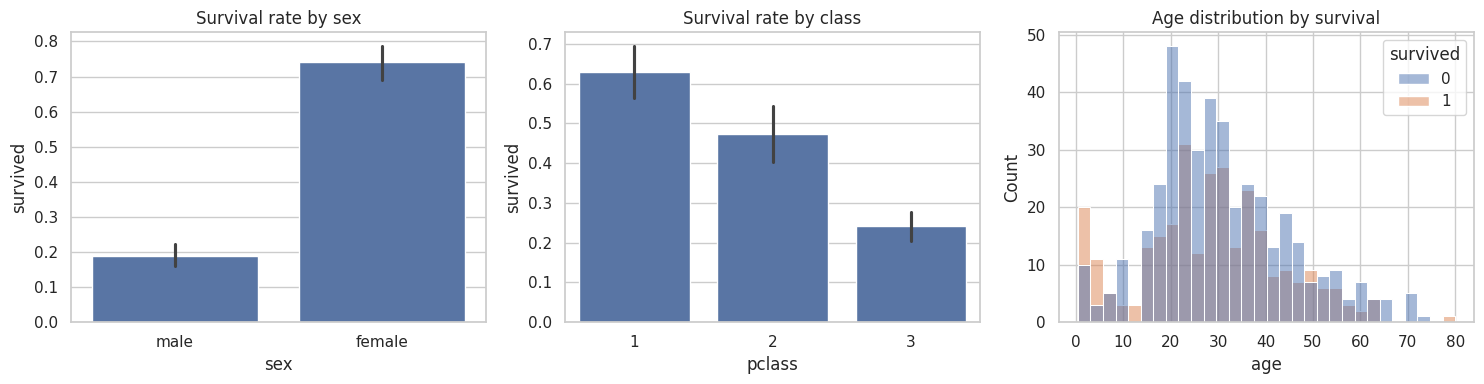

Overall survival rate: 0.384


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=df, x='sex', y='survived', ax=ax[0]); ax[0].set_title('Survival rate by sex')
sns.barplot(data=df, x='pclass', y='survived', ax=ax[1]); ax[1].set_title('Survival rate by class')
sns.histplot(data=df, x='age', hue='survived', bins=30, ax=ax[2]); ax[2].set_title('Age distribution by survival')
plt.tight_layout(); plt.show()
print('Overall survival rate:', round(df['survived'].mean(), 3))

## 2. Choose features and split the data
- We **drop `deck`**: about 77% missing, too much to fill reliably.
- We **drop `class`, `who`, `adult_male`, `alive`, `embark_town`, `alone`**: they duplicate other columns (or `alive` is the target in disguise, which would be **leakage**).
- Features kept: numeric `age, fare, sibsp, parch, pclass`; categorical `sex, embarked`.

In [5]:
num_cols = ['age', 'fare', 'sibsp', 'parch', 'pclass']
cat_cols = ['sex', 'embarked']
X = df[num_cols + cat_cols]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)
print('Survival rate  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

(712, 7) (179, 7)
Survival rate  train: 0.383  test: 0.385


**Why `stratify=y`?** It keeps the survival rate about the same in the train and test sets, so the split is fair.

**The golden rule:** split **first**, then learn anything (averages, categories, scaling) from the **training set only**. If you compute them on the full dataset, information from the test set leaks into training and your test score becomes too optimistic. This is called **data leakage**.

## 3. Handle missing data (step by step, fit on TRAIN only)

In [6]:
# Numeric: fill missing age with the MEDIAN of the training set
num_imputer = SimpleImputer(strategy='median').fit(X_train[num_cols])
print('Medians learned from TRAIN:', dict(zip(num_cols, num_imputer.statistics_.round(2))))
print('Median age on full data   :', df['age'].median(), '(slightly different: that is the leakage we avoid)')

# Categorical: fill missing embarked with the MOST FREQUENT value of the training set
cat_imputer = SimpleImputer(strategy='most_frequent').fit(X_train[cat_cols])
print('Most frequent categories from TRAIN:', cat_imputer.statistics_)

Medians learned from TRAIN: {'age': np.float64(28.5), 'fare': np.float64(14.45), 'sibsp': np.float64(0.0), 'parch': np.float64(0.0), 'pclass': np.float64(3.0)}
Median age on full data   : 28.0 (slightly different: that is the leakage we avoid)
Most frequent categories from TRAIN: ['male' 'S']


In [7]:
Xtr_num = pd.DataFrame(num_imputer.transform(X_train[num_cols]), columns=num_cols, index=X_train.index)
Xte_num = pd.DataFrame(num_imputer.transform(X_test[num_cols]),  columns=num_cols, index=X_test.index)
Xtr_cat = pd.DataFrame(cat_imputer.transform(X_train[cat_cols]), columns=cat_cols, index=X_train.index)
Xte_cat = pd.DataFrame(cat_imputer.transform(X_test[cat_cols]),  columns=cat_cols, index=X_test.index)
print('Missing left in train:', Xtr_num.isnull().sum().sum() + Xtr_cat.isnull().sum().sum())

Missing left in train: 0


## 4. Encode categories and scale numbers
- **One-hot encoding:** models need numbers, not text. `sex` becomes columns like `sex_female`, `sex_male` with 0/1 values.
- **Scaling:** `fare` is in the hundreds while `sibsp` is 0-8. Scaling puts features on a similar scale (mean 0, standard deviation 1). Models like kNN and logistic regression need it; trees don't.

In [8]:
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(Xtr_cat)
Xtr_oh = pd.DataFrame(ohe.transform(Xtr_cat), columns=ohe.get_feature_names_out(cat_cols), index=Xtr_cat.index)
Xte_oh = pd.DataFrame(ohe.transform(Xte_cat), columns=ohe.get_feature_names_out(cat_cols), index=Xte_cat.index)
display(Xtr_oh.head())

scaler = StandardScaler().fit(Xtr_num)
Xtr_sc = pd.DataFrame(scaler.transform(Xtr_num), columns=num_cols, index=Xtr_num.index)
Xte_sc = pd.DataFrame(scaler.transform(Xte_num), columns=num_cols, index=Xte_num.index)
print('Before scaling:'); display(Xtr_num.describe().loc[['mean','std']].round(2))
print('After scaling :'); display(Xtr_sc.describe().loc[['mean','std']].round(2))

,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
692,0.0,1.0,0.0,0.0,1.0
481,0.0,1.0,0.0,0.0,1.0
527,0.0,1.0,0.0,0.0,1.0
855,1.0,0.0,0.0,0.0,1.0
801,1.0,0.0,0.0,0.0,1.0


Before scaling:


,age,fare,sibsp,parch,pclass
mean,29.56,31.82,0.49,0.39,2.31
std,13.03,48.06,1.06,0.84,0.83


After scaling :


,age,fare,sibsp,parch,pclass
mean,0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0


In [9]:
# Put the pieces back together
Xtr_final = pd.concat([Xtr_sc, Xtr_oh], axis=1)
Xte_final = pd.concat([Xte_sc, Xte_oh], axis=1)
print(Xtr_final.shape); display(Xtr_final.head())

(712, 10)


,age,fare,sibsp,parch,pclass,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
692,-0.081135,0.513812,-0.465084,-0.466183,0.829568,0.0,1.0,0.0,0.0,1.0
481,-0.081135,-0.662563,-0.465084,-0.466183,-0.370945,0.0,1.0,0.0,0.0,1.0
527,-0.081135,3.955399,-0.465084,-0.466183,-1.571457,0.0,1.0,0.0,0.0,1.0
855,-0.887827,-0.467874,-0.465084,0.727782,0.829568,1.0,0.0,0.0,0.0,1.0
801,0.110934,-0.115977,0.478335,0.727782,-0.370945,1.0,0.0,0.0,0.0,1.0


## 5. Baseline model and a single train/test score

In [10]:
model = LogisticRegression(max_iter=1000).fit(Xtr_final, y_train)
print('Train accuracy:', round(model.score(Xtr_final, y_train), 3))
print('Test accuracy :', round(model.score(Xte_final, y_test), 3))

Train accuracy: 0.808
Test accuracy : 0.804


Also compare with the **majority-class baseline**: always predicting 'did not survive'. Your model should beat this.

In [11]:
print('Baseline (always predict the majority class):', round(1 - y_test.mean(), 3))

Baseline (always predict the majority class): 0.615


## 6. Why one split is not enough: cross-validation
A single split gives one score, and it depends on *which* rows happened to land in the test set. Try different random splits and watch the score move.

In [12]:
 # Same preprocessing + model wrapped in a Pipeline (we study Pipelines properly on Wednesday).
# A Pipeline refits the imputer, encoder and scaler on each training fold, which avoids leakage.
preprocess = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])
pipe = Pipeline([('prep', preprocess), ('clf', LogisticRegression(max_iter=1000))])

# 1) Different single splits give different scores
scores = []
for seed in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed, stratify=y)
    scores.append(pipe.fit(Xa, ya).score(Xb, yb))
print('10 different splits:', np.round(scores, 3))
print('min =', round(min(scores), 3), ' max =', round(max(scores), 3))

10 different splits: [0.782 0.788 0.788 0.827 0.816 0.793 0.793 0.76  0.855 0.81 ]
min = 0.76  max = 0.855


5 fold scores: [0.771 0.803 0.792 0.781 0.82 ]
Mean = 0.794  Std = 0.017


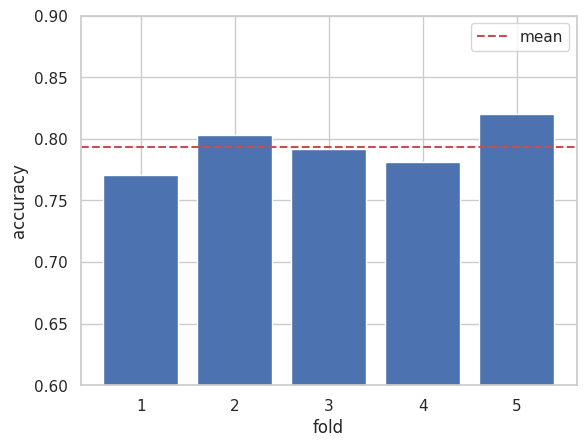

In [13]:
# 2) 5-fold cross-validation: every row is used for testing exactly once
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(pipe, X, y, cv=cv)
print('5 fold scores:', np.round(cv_scores, 3))
print(f'Mean = {cv_scores.mean():.3f}  Std = {cv_scores.std():.3f}')
plt.bar(range(1, 6), cv_scores); plt.axhline(cv_scores.mean(), color='r', ls='--', label='mean')
plt.ylim(0.6, 0.9); plt.xlabel('fold'); plt.ylabel('accuracy'); plt.legend(); plt.show()

**How 5-fold CV works:** the data is cut into 5 parts. Each part takes one turn as the test set while the other 4 train the model. You get 5 scores, and the **mean** is a more reliable estimate than a single split, while the **standard deviation** shows how stable it is.